# Diabetes Risk Classification on CDC BRFSS Health Indicators

**Dataset:** CDC Diabetes Health Indicators (UCI id 891), from the CDC's BRFSS telephone health survey (2015). About 253,000 respondents, 21 health/lifestyle/demographic features. Target `Diabetes_binary`: 0 = no diabetes, 1 = prediabetes or diabetes.

**Why this dataset:** large, real population-scale data, and a realistic **class imbalance** (~14% positive). That makes calibration, threshold choice and subgroup checks meaningful. All of it is self-reported survey data (no lab values), so this is a *screening / risk-stratification* model, not a diagnostic one.

**Design**

| Step | Choice |
|---|---|
| Split | **Train / Validation / Test = 70 / 15 / 15**, stratified, after removing exact duplicate rows (prevents train/test leakage) |
| Imbalance | Cost-sensitive learning (class weights), no synthetic oversampling |
| Features | Domain-motivated engineered features (risk-factor count, lifestyle score, interactions) |
| Feature selection | **Compared 4 methods** (none, ANOVA top-k, L1 logistic, XGBoost importance); best one used inside the pipeline (no leakage) |
| Models | Logistic Regression, **SVM** (RBF, trained on a stratified subsample, as SVMs scale poorly), Random Forest, XGBoost + stacking ensemble |
| Tuning | Optuna (Bayesian) on a stratified subsample, optimizing **PR-AUC** |
| Calibration | Isotonic calibration fit on validation part A, checked on part B |
| Threshold | Chosen on validation part B (F2, recall-weighted) |
| Test | Used once, with bootstrap 95% CIs |
| Extras | Ablation study, SHAP, **subgroup performance (sex / age / income)** |

In [19]:
!pip -q install shap optuna xgboost ucimlrepo

In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings, joblib
warnings.filterwarnings('ignore')

import optuna
import shap
from xgboost import XGBClassifier

from sklearn import set_config
from sklearn.base import BaseEstimator, ClassifierMixin, TransformerMixin
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.feature_selection import SelectKBest, SelectFromModel, f_classif
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.isotonic import IsotonicRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.calibration import CalibrationDisplay, CalibratedClassifierCV
from sklearn.inspection import permutation_importance
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_validate
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, brier_score_loss,
                             precision_recall_curve, RocCurveDisplay,
                             PrecisionRecallDisplay, ConfusionMatrixDisplay)

set_config(transform_output='pandas')
optuna.logging.set_verbosity(optuna.logging.WARNING)
sns.set_style('whitegrid')

RS = 42
N_TRIALS = 20     # Optuna trials per model; raise for a deeper search
TUNE_N = 30000    # rows used for tuning/ablation CV (final models train on ALL training rows)
N_BOOT = 300      # bootstrap resamples for test confidence intervals
SVM_MAX = 10000   # max rows per SVM fit (kernel SVMs do not scale to 200K rows)
print('Setup done')

Setup done


## 1. Load data

Loaded with `ucimlrepo` (UCI id 891). If that fails, download the CSV from Kaggle (`diabetes_binary_health_indicators_BRFSS2015.csv`, https://www.kaggle.com/datasets/alexteboul/diabetes-health-indicators-dataset) and upload it when asked.

In [21]:
# LOAD
try:
    from ucimlrepo import fetch_ucirepo
    ds = fetch_ucirepo(id=891)
    df = pd.concat([ds.data.features, ds.data.targets], axis=1)
    print('Loaded from UCI (id 891)')
except Exception as e:
    print('UCI load failed:', e)
    from google.colab import files
    up = files.upload()
    df = pd.read_csv(list(up.keys())[0])

df = df.drop(columns=[c for c in ['ID'] if c in df.columns])
if 'Diabetes_binary' not in df.columns and 'Diabetes_012' in df.columns:
    df['Diabetes_binary'] = (df['Diabetes_012'] > 0).astype(int)
    df = df.drop(columns='Diabetes_012')
assert 'Diabetes_binary' in df.columns, f'Target not found. Columns: {list(df.columns)}'
df = df.apply(pd.to_numeric)
TARGET = 'Diabetes_binary'
df[TARGET] = df[TARGET].astype(int)
print(df.shape)
print(list(df.columns))
df.head()

Loaded from UCI (id 891)
(253680, 22)
['HighBP', 'HighChol', 'CholCheck', 'BMI', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth', 'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education', 'Income', 'Diabetes_binary']


,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,...,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income,Diabetes_binary
0,1,1,1,40,1,0,0,0,0,1,...,0,5,18,15,1,0,9,4,3,0
1,0,0,0,25,1,0,0,1,0,0,...,1,3,0,0,0,0,7,6,1,0
2,1,1,1,28,0,0,0,0,1,0,...,1,5,30,30,1,0,9,4,8,0
3,1,0,1,27,0,0,0,1,1,1,...,0,2,0,0,0,0,11,3,6,0
4,1,1,1,24,0,0,0,1,1,1,...,0,2,3,0,0,0,11,5,4,0


## 2. Data quality: missing values and duplicates

BRFSS contains many exact duplicate rows (different people with identical answers to these 21 questions). If copies land in both train and test, scores are inflated, so exact duplicates are removed **before** splitting. This is a conservative choice and slightly changes the class balance.

In [22]:
print('Missing values:', int(df.isna().sum().sum()))
n_before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f'Duplicates removed: {n_before - len(df):,}  ->  {len(df):,} rows remain')
print('\nClass balance after de-duplication:')
print(df[TARGET].value_counts().rename({0: 'No diabetes', 1: 'Prediabetes/diabetes'}))
print(f'Prevalence: {df[TARGET].mean():.3f}   (a model that always predicts "no" gets {1 - df[TARGET].mean():.1%} accuracy, so accuracy is misleading here)')

Missing values: 0
Duplicates removed: 24,206  ->  229,474 rows remain

Class balance after de-duplication:
Diabetes_binary
No diabetes             194377
Prediabetes/diabetes     35097
Name: count, dtype: int64
Prevalence: 0.153   (a model that always predicts "no" gets 84.7% accuracy, so accuracy is misleading here)


## 3. Exploratory data analysis

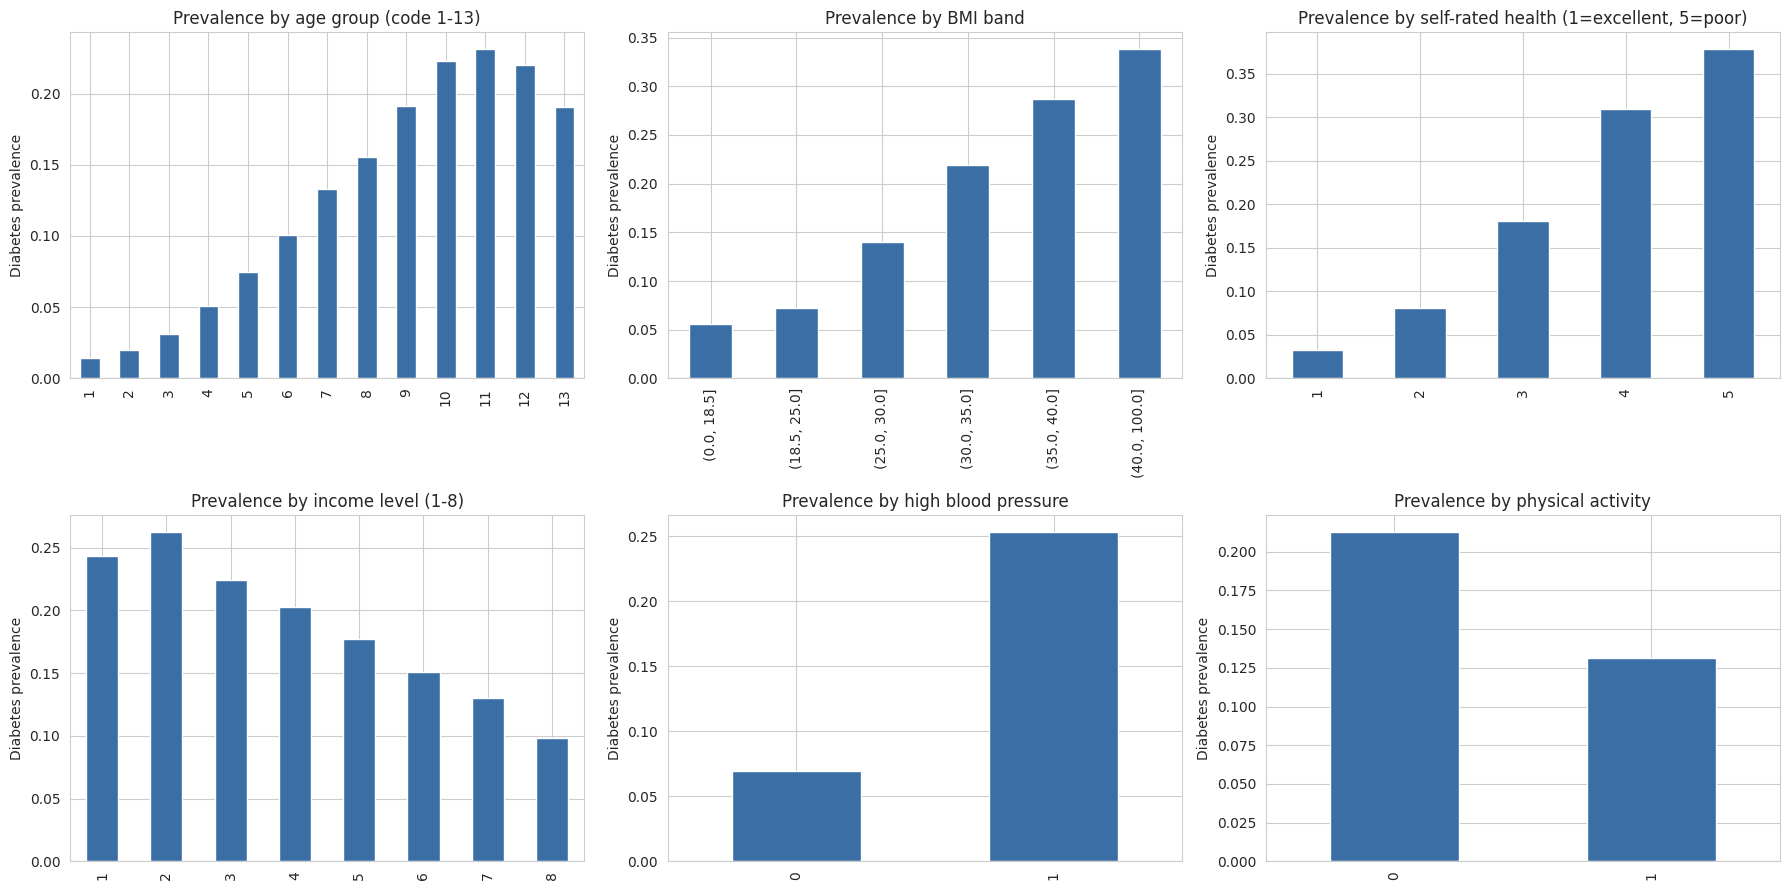

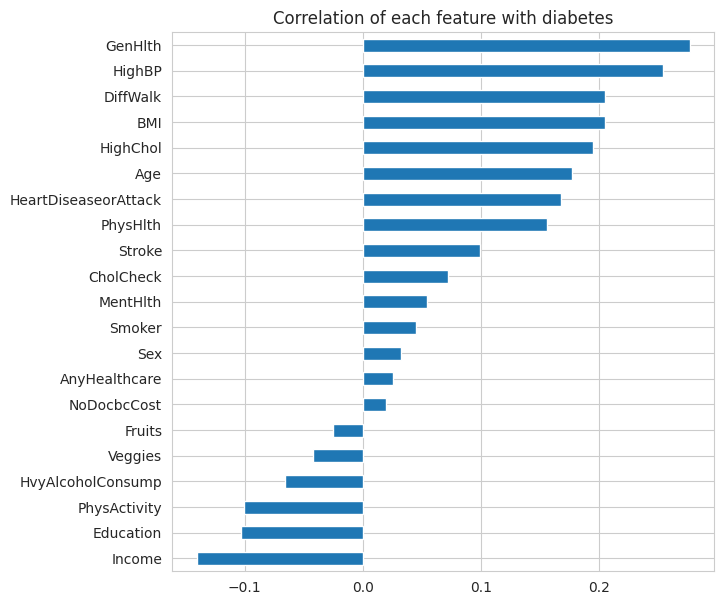

In [23]:
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
def prev_plot(ax, col, title, bins=None):
    s = pd.cut(df[col], bins=bins) if bins is not None else df[col]
    df.groupby(s)[TARGET].mean().plot(kind='bar', ax=ax, color='#3b6ea5')
    ax.set_title(title); ax.set_ylabel('Diabetes prevalence'); ax.set_xlabel('')

if 'Age' in df: prev_plot(axes[0, 0], 'Age', 'Prevalence by age group (code 1-13)')
if 'BMI' in df: prev_plot(axes[0, 1], 'BMI', 'Prevalence by BMI band', bins=[0, 18.5, 25, 30, 35, 40, 100])
if 'GenHlth' in df: prev_plot(axes[0, 2], 'GenHlth', 'Prevalence by self-rated health (1=excellent, 5=poor)')
if 'Income' in df: prev_plot(axes[1, 0], 'Income', 'Prevalence by income level (1-8)')
if 'HighBP' in df: prev_plot(axes[1, 1], 'HighBP', 'Prevalence by high blood pressure')
if 'PhysActivity' in df: prev_plot(axes[1, 2], 'PhysActivity', 'Prevalence by physical activity')
plt.tight_layout(); plt.show()

corr_t = df.corr()[TARGET].drop(TARGET).sort_values()
corr_t.plot(kind='barh', figsize=(7, 7), title='Correlation of each feature with diabetes')
plt.show()

## 4. Train / Validation / Test split (70 / 15 / 15, stratified)

| Set | Used for |
|---|---|
| **Train** | fitting models |
| **Validation** | choosing the final model, calibration, choosing the decision threshold |
| **Test** | final one-time report, never used for any decision |

Validation is further halved: **part A** fits the calibrator, **part B** checks calibration and picks the threshold (so those two decisions don't reuse the same rows).

In [24]:
X = df.drop(columns=TARGET)
y = df[TARGET]

X_trainval, X_test, y_trainval, y_test = train_test_split(
    X, y, test_size=0.15, stratify=y, random_state=RS)
X_train, X_val, y_train, y_val = train_test_split(
    X_trainval, y_trainval, test_size=0.15 / 0.85, stratify=y_trainval, random_state=RS)
X_valA, X_valB, y_valA, y_valB = train_test_split(
    X_val, y_val, test_size=0.5, stratify=y_val, random_state=RS)

for name, yy in [('Train', y_train), ('Validation', y_val), ('  Val A (calibrate)', y_valA),
                 ('  Val B (threshold)', y_valB), ('Test', y_test)]:
    print(f'{name:<20} n={len(yy):>7,}   positive rate={yy.mean():.3f}')

SPW = (y_train == 0).sum() / (y_train == 1).sum()   # imbalance weight for XGBoost

# stratified subsample used only for tuning / ablation (keeps Optuna fast)
if len(X_train) > TUNE_N:
    X_tune, _, y_tune, _ = train_test_split(X_train, y_train, train_size=TUNE_N,
                                            stratify=y_train, random_state=RS)
else:
    X_tune, y_tune = X_train, y_train
print('Tuning subsample:', X_tune.shape)

Train                n=160,631   positive rate=0.153
Validation           n= 34,421   positive rate=0.153
  Val A (calibrate)  n= 17,210   positive rate=0.153
  Val B (threshold)  n= 17,211   positive rate=0.153
Test                 n= 34,422   positive rate=0.153
Tuning subsample: (30000, 21)


## 5. Pipeline building blocks

`ClinicalFeatures` adds domain-motivated features: a cardiometabolic **risk-factor count**, a **lifestyle score**, BMI obesity flag and non-linear BMI term, age/health/BMI interactions, total unwell days and a socio-economic composite. It only creates a feature if the needed columns exist.

In [25]:
class ClinicalFeatures(BaseEstimator, TransformerMixin):
    """Adds domain-motivated features to a DataFrame of BRFSS indicators."""
    def fit(self, X, y=None):
        # recorded so sklearn meta-estimators (e.g. StackingClassifier) can introspect the pipeline
        self.n_features_in_ = X.shape[1]
        self.feature_names_in_ = np.array(X.columns, dtype=object)
        return self

    def transform(self, X):
        X = X.copy()
        has = lambda *cols: all(c in X.columns for c in cols)
        if has('BMI'):
            X['BMI_obese'] = (X['BMI'] >= 30).astype(int)
            X['BMI_sq'] = X['BMI'] ** 2 / 100
        risk = [c for c in ['HighBP', 'HighChol', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'DiffWalk']
                if c in X.columns]
        if risk:
            X['RiskCount'] = X[risk].sum(axis=1)
        if has('HighBP', 'HighChol'):
            X['HighBP_HighChol'] = X['HighBP'] * X['HighChol']
        if has('GenHlth', 'Age'):
            X['GenHlth_Age'] = X['GenHlth'] * X['Age']
        if has('BMI', 'Age'):
            X['BMI_Age'] = X['BMI'] * X['Age'] / 10
        if has('MentHlth', 'PhysHlth'):
            X['UnwellDays'] = X['MentHlth'] + X['PhysHlth']
        if has('PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'Smoker'):
            X['LifestyleScore'] = (X['PhysActivity'] + X['Fruits'] + X['Veggies']
                                   - X['HvyAlcoholConsump'] - X['Smoker'])
        if has('Education', 'Income'):
            X['SES'] = X['Education'] + X['Income']
        return X


class SubsampledSVM(ClassifierMixin, BaseEstimator):
    """RBF-SVM with Platt-calibrated probabilities. Kernel SVMs scale ~O(n^2), so each fit uses a
    stratified subsample of at most `max_samples` rows (the full training set is far too big)."""
    def __init__(self, C=1.0, gamma=0.03, max_samples=10000, random_state=42):
        self.C = C
        self.gamma = gamma
        self.max_samples = max_samples
        self.random_state = random_state

    def fit(self, X, y):
        X, y = np.asarray(X), np.asarray(y)
        if len(y) > self.max_samples:
            X, _, y, _ = train_test_split(X, y, train_size=self.max_samples,
                                          stratify=y, random_state=self.random_state)
        base = SVC(C=self.C, gamma=self.gamma, kernel='rbf', class_weight='balanced')
        self.model_ = CalibratedClassifierCV(base, method='sigmoid', cv=3).fit(X, y)
        self.classes_ = self.model_.classes_
        return self

    def predict_proba(self, X):
        return self.model_.predict_proba(np.asarray(X))

    def predict(self, X):
        return self.classes_[np.argmax(self.predict_proba(X), axis=1)]


# Feature-selection candidates (all are used INSIDE the pipeline, so they are re-fit on each CV
# training fold only and never see validation/test data).
SELECTORS = {
    'None (all features)': lambda: 'passthrough',
    'ANOVA top-20':        lambda: SelectKBest(f_classif, k=20),
    'L1 logistic':         lambda: SelectFromModel(LogisticRegression(penalty='l1', solver='liblinear', C=0.05,
                                                                     class_weight='balanced', random_state=RS)),
    'XGBoost importance':  lambda: SelectFromModel(XGBClassifier(n_estimators=100, max_depth=3, tree_method='hist',
                                                                 random_state=RS, n_jobs=-1), threshold='median'),
}
CHOSEN_SELECTOR = 'None (all features)'   # replaced after the feature-selection comparison (section 7)


def build_pipe(model, fe=True, sel=None):
    sel = CHOSEN_SELECTOR if sel is None else sel
    steps = []
    if fe:
        steps.append(('fe', ClinicalFeatures()))
    steps += [('scaler', StandardScaler()), ('select', SELECTORS[sel]()), ('clf', model)]
    return Pipeline(steps)


def model_from_params(name, p):
    if name == 'Logistic Regression':
        return LogisticRegression(C=p['C'], class_weight='balanced', max_iter=3000, random_state=RS)
    if name == 'SVM':
        return SubsampledSVM(C=p['C'], gamma=p['gamma'], max_samples=SVM_MAX, random_state=RS)
    if name == 'Random Forest':
        return RandomForestClassifier(n_estimators=p['n_estimators'], max_depth=p['max_depth'],
                                      min_samples_leaf=p['min_samples_leaf'], max_features=p['max_features'],
                                      class_weight='balanced_subsample', random_state=RS, n_jobs=-1)
    if name == 'XGBoost':
        return XGBClassifier(n_estimators=p['n_estimators'], max_depth=p['max_depth'],
                             learning_rate=p['learning_rate'], subsample=p['subsample'],
                             colsample_bytree=p['colsample_bytree'], min_child_weight=p['min_child_weight'],
                             reg_lambda=p['reg_lambda'], scale_pos_weight=SPW, tree_method='hist',
                             eval_metric='logloss', random_state=RS, n_jobs=-1)


def sample_params(name, t):
    if name == 'Logistic Regression':
        return {'C': t.suggest_float('C', 1e-3, 1e2, log=True)}
    if name == 'SVM':
        return {'C': t.suggest_float('C', 0.1, 10, log=True),
                'gamma': t.suggest_float('gamma', 1e-3, 1e-1, log=True)}
    if name == 'Random Forest':
        return {'n_estimators': t.suggest_int('n_estimators', 100, 300, step=50),
                'max_depth': t.suggest_int('max_depth', 6, 14),
                'min_samples_leaf': t.suggest_int('min_samples_leaf', 5, 50),
                'max_features': t.suggest_categorical('max_features', ['sqrt', 'log2', 0.5])}
    if name == 'XGBoost':
        return {'n_estimators': t.suggest_int('n_estimators', 100, 500, step=50),
                'max_depth': t.suggest_int('max_depth', 2, 7),
                'learning_rate': t.suggest_float('learning_rate', 0.01, 0.2, log=True),
                'subsample': t.suggest_float('subsample', 0.6, 1.0),
                'colsample_bytree': t.suggest_float('colsample_bytree', 0.6, 1.0),
                'min_child_weight': t.suggest_int('min_child_weight', 1, 20),
                'reg_lambda': t.suggest_float('reg_lambda', 1e-2, 10, log=True)}


MODEL_NAMES = ['Logistic Regression', 'SVM', 'Random Forest', 'XGBoost']
cv_tune = StratifiedKFold(n_splits=5, shuffle=True, random_state=RS)
print('Helpers ready')

Helpers ready


## 6. Ablation study: did feature engineering actually help?

Same models with and without the engineered features, 5-fold CV on the tuning subsample. This is the evidence for the modification, whichever way it turns out.

In [26]:
default_models = {
    'Logistic Regression': lambda: LogisticRegression(max_iter=3000, class_weight='balanced', random_state=RS),
    'XGBoost': lambda: XGBClassifier(tree_method='hist', eval_metric='logloss',
                                     scale_pos_weight=SPW, random_state=RS, n_jobs=-1),
}
rows = []
for vname, fe in [('A. Raw features (usual)', False), ('B. + clinical feature engineering', True)]:
    row = {'Features': vname}
    for mname, mk in default_models.items():
        res = cross_validate(build_pipe(mk(), fe=fe), X_tune, y_tune, cv=cv_tune,
                             scoring=['average_precision', 'roc_auc'], n_jobs=1)
        row[mname + ' PR-AUC'] = f"{res['test_average_precision'].mean():.3f} +/- {res['test_average_precision'].std():.3f}"
        row[mname + ' ROC-AUC'] = f"{res['test_roc_auc'].mean():.3f} +/- {res['test_roc_auc'].std():.3f}"
    rows.append(row)

ablation = pd.DataFrame(rows).set_index('Features')
ablation.T

Features,A. Raw features (usual),B. + clinical feature engineering
Logistic Regression PR-AUC,0.393 +/- 0.005,0.414 +/- 0.005
Logistic Regression ROC-AUC,0.803 +/- 0.004,0.806 +/- 0.005
XGBoost PR-AUC,0.374 +/- 0.005,0.374 +/- 0.011
XGBoost ROC-AUC,0.779 +/- 0.004,0.779 +/- 0.005


## 7. Feature selection

Four strategies are compared (with 5-fold CV on the tuning subsample, using Logistic Regression and XGBoost as probes). Selection happens **inside the pipeline**, so each fold selects features from its own training part only.

The winner is the method with the best average PR-AUC; if several are within 0.002 of the best, the one with **fewer features** is chosen (simpler model, same performance).

,Features kept,Logistic Regression PR-AUC,XGBoost PR-AUC,Mean PR-AUC
Method,,,,
None (all features),30,0.4145,0.3741,0.3943
ANOVA top-20,20,0.4103,0.3707,0.3905
L1 logistic,26,0.4145,0.3775,0.3960
XGBoost importance,15,0.3933,0.3718,0.3826



Chosen feature selection: L1 logistic  (26 of 30 features)
Features kept: ['HighBP', 'HighChol', 'CholCheck', 'BMI', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth', 'PhysHlth', 'Sex', 'Age', 'Income', 'BMI_obese', 'BMI_sq', 'RiskCount', 'HighBP_HighChol', 'GenHlth_Age', 'BMI_Age', 'UnwellDays', 'LifestyleScore', 'SES']
Features dropped: ['Veggies', 'MentHlth', 'DiffWalk', 'Education']


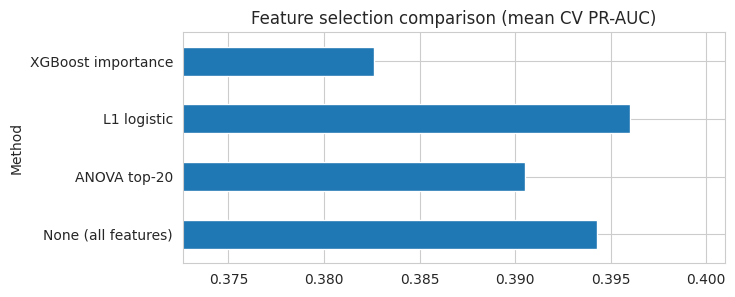

In [27]:
probe_models = {
    'Logistic Regression': lambda: LogisticRegression(max_iter=3000, class_weight='balanced', random_state=RS),
    'XGBoost': lambda: XGBClassifier(tree_method='hist', eval_metric='logloss',
                                     scale_pos_weight=SPW, random_state=RS, n_jobs=-1),
}

# how many features does each method keep when fit on the full tuning subsample?
n_kept, kept_names = {}, {}
fe_cols = ClinicalFeatures().transform(X_tune.head(5)).columns
for sname in SELECTORS:
    pipe = build_pipe(probe_models['Logistic Regression'](), fe=True, sel=sname).fit(X_tune, y_tune)
    mask = pipe[:-1].transform(X_tune.head(5)).columns
    n_kept[sname], kept_names[sname] = len(mask), list(mask)

fs_rows = []
for sname in SELECTORS:
    row = {'Method': sname, 'Features kept': n_kept[sname]}
    scores = []
    for mname, mk in probe_models.items():
        res = cross_validate(build_pipe(mk(), fe=True, sel=sname), X_tune, y_tune, cv=cv_tune,
                             scoring='average_precision', n_jobs=1)
        row[mname + ' PR-AUC'] = round(res['test_score'].mean(), 4)
        scores.append(res['test_score'].mean())
    row['Mean PR-AUC'] = round(float(np.mean(scores)), 4)
    fs_rows.append(row)

fs_table = pd.DataFrame(fs_rows).set_index('Method')
display(fs_table)

best_mean = fs_table['Mean PR-AUC'].max()
near_best = fs_table[fs_table['Mean PR-AUC'] >= best_mean - 0.002]
CHOSEN_SELECTOR = near_best['Features kept'].idxmin()
print(f'\nChosen feature selection: {CHOSEN_SELECTOR}  ({n_kept[CHOSEN_SELECTOR]} of {len(fe_cols)} features)')
print('Features kept:', kept_names[CHOSEN_SELECTOR])
dropped = [c for c in fe_cols if c not in kept_names[CHOSEN_SELECTOR]]
print('Features dropped:', dropped if dropped else 'none')

fs_table['Mean PR-AUC'].plot(kind='barh', figsize=(7, 3), title='Feature selection comparison (mean CV PR-AUC)')
plt.xlim(fs_table['Mean PR-AUC'].min() - 0.01, best_mean + 0.005)
plt.show()

## 8. Bayesian hyperparameter tuning (Optuna, objective = PR-AUC)

PR-AUC is used instead of ROC-AUC because it reflects performance on the rare positive class much better when only ~14% of people are positive.

In [28]:
def make_objective(name):
    def objective(trial):
        p = sample_params(name, trial)
        pipe = build_pipe(model_from_params(name, p))
        return cross_val_score(pipe, X_tune, y_tune, cv=cv_tune,
                               scoring='average_precision', n_jobs=1).mean()
    return objective

best_params, tune_rows = {}, []
for name in MODEL_NAMES:
    study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=RS))
    study.optimize(make_objective(name), n_trials=N_TRIALS)
    best_params[name] = study.best_params
    tune_rows.append({'Model': name, 'Best CV PR-AUC (tuning subsample)': round(study.best_value, 3)})
    print(name, '->', study.best_params)

pd.DataFrame(tune_rows).set_index('Model')

Logistic Regression -> {'C': 89.82349942410399}
SVM -> {'C': 7.427150447067115, 'gamma': 0.0011029526064520745}
Random Forest -> {'n_estimators': 200, 'max_depth': 13, 'min_samples_leaf': 25, 'max_features': 'sqrt'}
XGBoost -> {'n_estimators': 350, 'max_depth': 4, 'learning_rate': 0.020322949034200857, 'subsample': 0.7439296552214119, 'colsample_bytree': 0.9918831289131909, 'min_child_weight': 3, 'reg_lambda': 4.009557557237132}


,Best CV PR-AUC (tuning subsample)
Model,
Logistic Regression,0.415
SVM,0.411
Random Forest,0.419
XGBoost,0.425


## 9. Fit on the full training set, add a stacking ensemble, compare on **validation**

This is the slowest cell (full-size Random Forest and the stacking ensemble). Expect several minutes on Colab.

In [29]:
fitted = {}
for name in MODEL_NAMES:
    fitted[name] = build_pipe(model_from_params(name, best_params[name])).fit(X_train, y_train)
    print('fitted', name)

stack = StackingClassifier(
    estimators=[(n.replace(' ', '_'), build_pipe(model_from_params(n, best_params[n]))) for n in MODEL_NAMES],
    final_estimator=LogisticRegression(max_iter=1000, random_state=RS),
    stack_method='predict_proba', cv=StratifiedKFold(3, shuffle=True, random_state=RS), n_jobs=1)
fitted['Stacking Ensemble'] = stack.fit(X_train, y_train)
print('fitted Stacking Ensemble')

val_rows = []
for name, m in fitted.items():
    pv = m.predict_proba(X_val)[:, 1]
    val_rows.append({'Model': name,
                     'PR-AUC': average_precision_score(y_val, pv),
                     'ROC-AUC': roc_auc_score(y_val, pv)})
val_table = pd.DataFrame(val_rows).set_index('Model').round(4).sort_values('PR-AUC', ascending=False)
print(f'Baseline PR-AUC of a random model = prevalence = {y_val.mean():.3f}')
display(val_table)

best_name = val_table.index[0]
raw_model = fitted[best_name]
print('Selected on validation set:', best_name)

fitted Logistic Regression
fitted SVM
fitted Random Forest
fitted XGBoost
fitted Stacking Ensemble
Baseline PR-AUC of a random model = prevalence = 0.153


,PR-AUC,ROC-AUC
Model,,
XGBoost,0.4344,0.8169
Stacking Ensemble,0.4340,0.8170
Random Forest,0.4291,0.8132
Logistic Regression,0.4244,0.8131
SVM,0.4223,0.8112


Selected on validation set: XGBoost


## 10. Probability calibration

Class weighting makes the model "pay more attention" to positives, so its raw scores are **not** real probabilities (they overstate risk). Isotonic regression, fit on validation part A, maps scores back to calibrated probabilities. We check the Brier score (lower is better) on validation part B, which the calibrator has never seen.

Brier on validation B:  raw = 0.1814   calibrated = 0.1067
Using calibrated probabilities


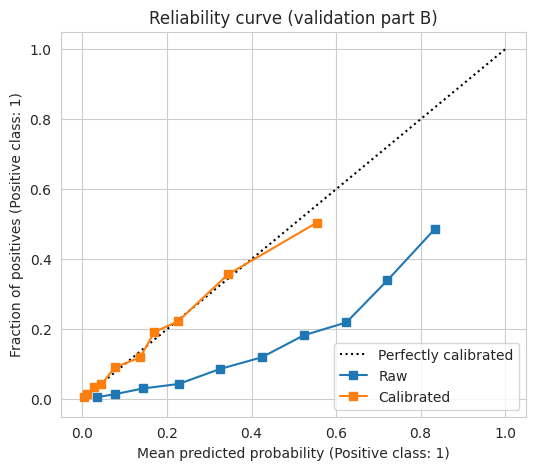

In [30]:
s_valA = raw_model.predict_proba(X_valA)[:, 1]
s_valB = raw_model.predict_proba(X_valB)[:, 1]

iso = IsotonicRegression(out_of_bounds='clip').fit(s_valA, y_valA)
c_valB = iso.predict(s_valB)

b_raw, b_cal = brier_score_loss(y_valB, s_valB), brier_score_loss(y_valB, c_valB)
print(f'Brier on validation B:  raw = {b_raw:.4f}   calibrated = {b_cal:.4f}')

USE_CAL = b_cal < b_raw
def predict_final(X_):
    s = raw_model.predict_proba(X_)[:, 1]
    return iso.predict(s) if USE_CAL else s
print('Using calibrated probabilities' if USE_CAL else 'Using raw probabilities')

fig, ax = plt.subplots(figsize=(6, 5))
CalibrationDisplay.from_predictions(y_valB, s_valB, n_bins=10, strategy='quantile', name='Raw', ax=ax)
CalibrationDisplay.from_predictions(y_valB, c_valB, n_bins=10, strategy='quantile', name='Calibrated', ax=ax)
ax.set_title('Reliability curve (validation part B)')
plt.show()

## 11. Decision threshold (chosen on validation part B)

For screening, missing a person with diabetes costs more than a false alarm, so the threshold maximizes **F2** (recall weighted 2x over precision) rather than using 0.5. In a real deployment this would be set from clinical cost/benefit.

Chosen threshold = 0.147   (validation-B F2 = 0.607)


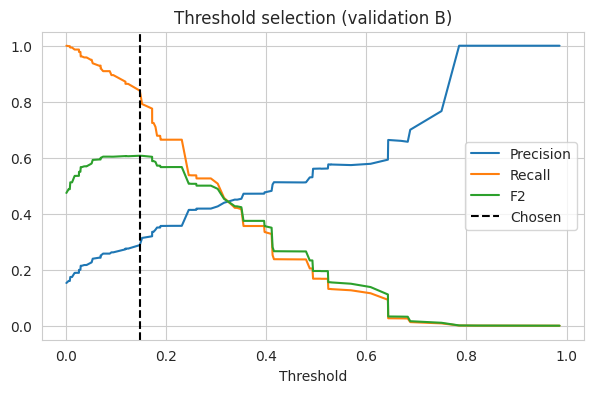

In [31]:
p_valB = predict_final(X_valB)
prec, rec, thr = precision_recall_curve(y_valB, p_valB)
prec, rec = prec[:-1], rec[:-1]
f2 = 5 * prec * rec / np.maximum(4 * prec + rec, 1e-12)
THRESHOLD = float(thr[np.argmax(f2)])
print(f'Chosen threshold = {THRESHOLD:.3f}   (validation-B F2 = {f2.max():.3f})')

plt.figure(figsize=(7, 4))
plt.plot(thr, prec, label='Precision'); plt.plot(thr, rec, label='Recall'); plt.plot(thr, f2, label='F2')
plt.axvline(THRESHOLD, color='k', ls='--', label='Chosen')
plt.xlabel('Threshold'); plt.legend(); plt.title('Threshold selection (validation B)'); plt.show()

## 12. Final evaluation on the **test** set (used once)

Reported at the default 0.5 threshold and at the validation-chosen threshold, with 95% bootstrap CIs.

,Threshold 0.5,Threshold 0.15 (validation-tuned)
Accuracy,"0.856 [0.853, 0.859]","0.660 [0.655, 0.665]"
Precision,"0.602 [0.578, 0.624]","0.291 [0.284, 0.298]"
Recall,"0.177 [0.168, 0.187]","0.855 [0.845, 0.864]"
F1,"0.274 [0.261, 0.287]","0.434 [0.426, 0.443]"
ROC-AUC,"0.822 [0.816, 0.826]","0.822 [0.816, 0.826]"
PR-AUC,"0.438 [0.425, 0.451]","0.438 [0.425, 0.451]"
Brier,"0.104 [0.103, 0.106]","0.104 [0.103, 0.106]"


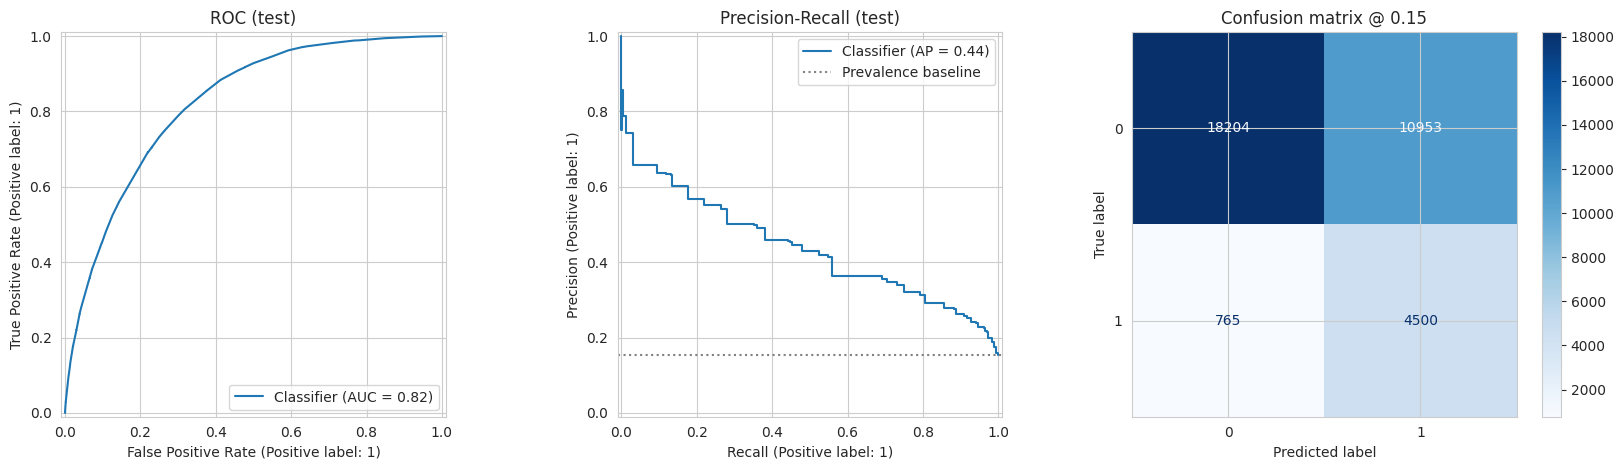

In [32]:
def metrics_at(yt, proba, thr):
    pred = (proba >= thr).astype(int)
    return {'Accuracy': accuracy_score(yt, pred),
            'Precision': precision_score(yt, pred, zero_division=0),
            'Recall': recall_score(yt, pred),
            'F1': f1_score(yt, pred),
            'ROC-AUC': roc_auc_score(yt, proba),
            'PR-AUC': average_precision_score(yt, proba),
            'Brier': brier_score_loss(yt, proba)}

p_test = predict_final(X_test)
yt = y_test.values
rng = np.random.default_rng(RS)
boot_idx = [rng.choice(len(yt), len(yt), replace=True) for _ in range(N_BOOT)]

def report(thr, label):
    point = metrics_at(yt, p_test, thr)
    boots = pd.DataFrame([metrics_at(yt[i], p_test[i], thr) for i in boot_idx])
    lo, hi = boots.quantile(0.025), boots.quantile(0.975)
    return pd.Series({k: f'{point[k]:.3f} [{lo[k]:.3f}, {hi[k]:.3f}]' for k in point}, name=label)

test_report = pd.DataFrame([report(0.5, 'Threshold 0.5'),
                            report(THRESHOLD, f'Threshold {THRESHOLD:.2f} (validation-tuned)')])
display(test_report.T)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
RocCurveDisplay.from_predictions(yt, p_test, ax=axes[0]); axes[0].set_title('ROC (test)')
PrecisionRecallDisplay.from_predictions(yt, p_test, ax=axes[1]); axes[1].set_title('Precision-Recall (test)')
axes[1].axhline(yt.mean(), color='gray', ls=':', label='Prevalence baseline'); axes[1].legend()
ConfusionMatrixDisplay.from_predictions(yt, (p_test >= THRESHOLD).astype(int), cmap='Blues', ax=axes[2])
axes[2].set_title(f'Confusion matrix @ {THRESHOLD:.2f}')
plt.tight_layout(); plt.show()

## 13. Subgroup performance (fairness check)

A model can look good overall and still work worse for some groups. We report performance on the test set by sex, age band and income band, at the chosen threshold. (Age codes 1-4 are roughly ages 18-39, 5-8 roughly 40-59, 9-13 roughly 60+, per the BRFSS codebook.)

In [33]:
te = X_test.copy()
te['y'] = yt
te['p'] = p_test

groups = {}
if 'Sex' in te: groups['Sex'] = te['Sex'].map({0: 'Female', 1: 'Male'})
if 'Age' in te: groups['Age band'] = pd.cut(te['Age'], [0, 4, 8, 13], labels=['codes 1-4 (~18-39)', 'codes 5-8 (~40-59)', 'codes 9-13 (~60+)'])
if 'Income' in te: groups['Income band'] = pd.cut(te['Income'], [0, 3, 6, 8], labels=['codes 1-3 (lowest)', 'codes 4-6', 'codes 7-8 (highest)'])

rows = []
for gname, g in groups.items():
    for level, sub in te.groupby(g, observed=True):
        if sub['y'].nunique() < 2:
            continue
        pred = (sub['p'] >= THRESHOLD).astype(int)
        rows.append({'Group': gname, 'Level': str(level), 'n': len(sub),
                     'Prevalence': round(sub['y'].mean(), 3),
                     'ROC-AUC': round(roc_auc_score(sub['y'], sub['p']), 3),
                     'PR-AUC': round(average_precision_score(sub['y'], sub['p']), 3),
                     'Recall': round(recall_score(sub['y'], pred), 3),
                     'Precision': round(precision_score(sub['y'], pred, zero_division=0), 3)})
subgroup_table = pd.DataFrame(rows).set_index(['Group', 'Level'])
subgroup_table

n  Prevalence  ROC-AUC  PR-AUC  Recall  \
Group       Level                                                             
Sex         Female               19075       0.142    0.835   0.441   0.844   
            Male                 15347       0.167    0.804   0.435   0.866   
Age band    codes 1-4 (~18-39)    5256       0.032    0.833   0.223   0.412   
            codes 5-8 (~40-59)   12096       0.125    0.828   0.409   0.780   
            codes 9-13 (~60+)    17070       0.210    0.772   0.457   0.907   
Income band codes 1-3 (lowest)    5652       0.247    0.788   0.523   0.924   
            codes 4-6            12083       0.170    0.805   0.437   0.879   
            codes 7-8 (highest)  16687       0.109    0.827   0.361   0.774   

                                 Precision  
Group       Level                           
Sex         Female                   0.292  
            Male                     0.290  
Age band    codes 1-4 (~18-39)       0.219  
            codes 5-8 (~40-59)       0.282  
            codes 9-13 (~60+)        0.297  
Income band codes 1-3 (lowest)       0.346  
            codes 4-6                0.291  
            codes 7-8 (highest)      0.255

## 14. Explainability

**SHAP** on the tuned XGBoost (explaining a 3,000-row test sample) shows how each feature pushes predicted risk up or down. **Permutation importance** is computed for the selected model on the same sample.

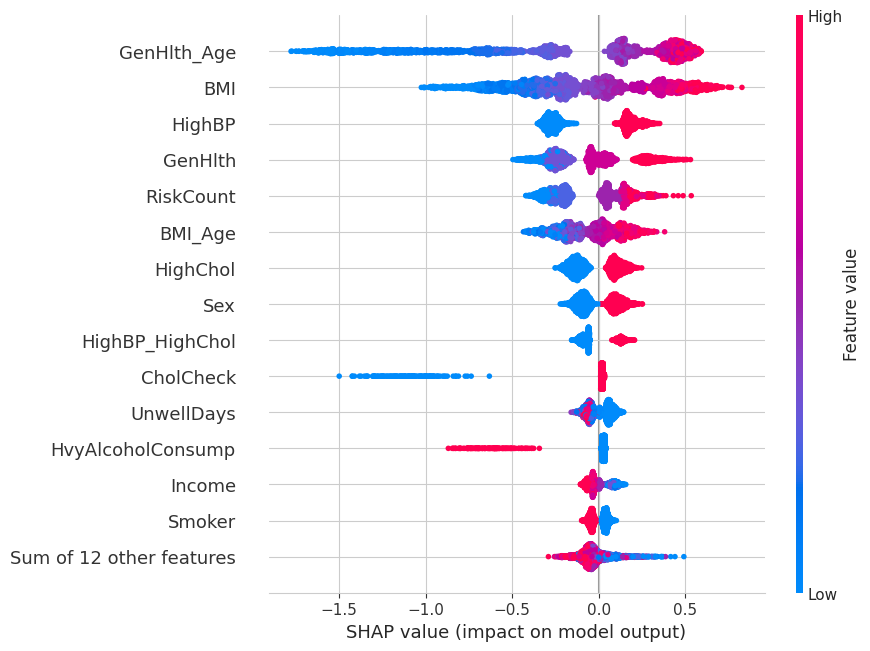

In [34]:
sample = X_test.sample(n=min(3000, len(X_test)), random_state=RS)
y_sample = y_test.loc[sample.index]

xgb_pipe = fitted['XGBoost']
Xt_sample = xgb_pipe[:-1].transform(sample)
explainer = shap.TreeExplainer(xgb_pipe.named_steps['clf'])
sv = explainer(Xt_sample)
shap.plots.beeswarm(sv, max_display=15)

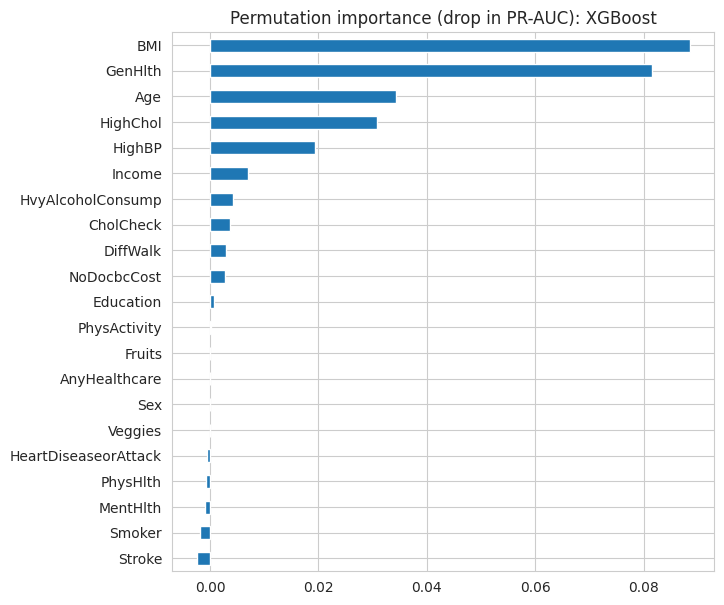

In [35]:
pi = permutation_importance(raw_model, sample, y_sample, scoring='average_precision',
                            n_repeats=5, random_state=RS)
imp = pd.Series(pi.importances_mean, index=sample.columns).sort_values()
imp.plot(kind='barh', figsize=(7, 7), title=f'Permutation importance (drop in PR-AUC): {best_name}')
plt.show()

## 15. Save outputs

In [36]:
ablation.to_csv('ablation_results.csv')
fs_table.to_csv('feature_selection_results.csv')
val_table.to_csv('validation_results.csv')
test_report.T.to_csv('test_results.csv')
subgroup_table.to_csv('subgroup_results.csv')
joblib.dump({'model': raw_model, 'calibrator': iso if USE_CAL else None, 'threshold': THRESHOLD},
            'diabetes_model.joblib')
print('Saved: ablation_results.csv, feature_selection_results.csv, validation_results.csv, test_results.csv, subgroup_results.csv, diabetes_model.joblib')

Saved: ablation_results.csv, feature_selection_results.csv, validation_results.csv, test_results.csv, subgroup_results.csv, diabetes_model.joblib


## Notes for the README

* The test set was used exactly once. Model choice, calibration and threshold came from train/validation only.
* Exact duplicate rows were removed before splitting to avoid leakage.
* Data are self-reported survey responses from one year (2015), so the model supports **screening / risk stratification**, not diagnosis, and may not transfer to other populations or years.
* The SVM is trained on a stratified subsample (kernel SVMs do not scale to 200K+ rows); the other models use all training rows.
* To reload the saved model, define the `ClinicalFeatures` and `SubsampledSVM` classes first, then `joblib.load`.